# DS 3000 Project Phase II: Proof of Concept

Your Names: Reyna Ahuja, Lea Choe, Isaac Song Hwang

Due: Thursday Nov 5 @ 11:59 PM EST

### Submission Instructions
Submit this `ipynb` file to Gradescope (this can also be done via the assignment on Canvas).  To ensure that your submitted `ipynb` file represents your latest code, make sure to give a fresh `Kernel > Restart & Run All` just before uploading the `ipynb` file to gradescope. **In addition:**
- Make sure your name is entered above
- Make sure you comment your code effectively
- If problems are difficult for the TAs/Profs to grade, you will lose points

### Tips for success
- Start early
- Make use of Discord
- Make use of Office Hours
- Remember to use cells and headings to make the notebook easy to read (if a grader cannot find the answer to a problem, you will receive no points for it)
- Under no circumstances may one student view or share their ungraded homework or quiz with another student [(see also)](http://www.northeastern.edu/osccr/academic-integrity), though you are welcome to **talk about** (*not* show each other your answers to) the problems.

### 1. (20 pts) Expresses the central motivation of the project and explains the (at least) two key questions to be explored. Gives a summary of the data processing pipeline so a technical expert can easily follow along.

*Adverse drug events (ADEs) occur when medications cause harm to individuals, and they are a serious public health threat that have caused more than 1.5 million emergency-department visits every year. Older adults (65+ year olds) make up more than 600,000 of these visits each year because they often take more medicine as they age. Although many adverse events are reported, not every report has the same severity. Some reports involve relatively less serious outcomes while others are defined by the FDA as serious adverse events, meaning they include hospitalization, disability, death, and other important events requiring intervention to prevent serious harm. This data science project may provide helpful insights by studying how patient and medication characteristics correlate with the seriousness of these reports to identify patterns associated with more severe outcomes.*
*The two key questions of interest include the following:*
1. *What patient and medication characteristics are associated with whether an adverse-event report is classified as serious versus non-serious?*
2. *Can these characteristics be used to predict whether an adverse-event report will involve hospitalization?*

*The data used to complete this project will be collected from the FDA Adverse Event Reporting System through the openFDA Drug Adverse Event API. In this API, each observation is one adverse-event report and includes patient demographic information, medication(s) involved, reactions reported, and seriousness of the ADE. To load the data, we will collect it directly in Python using the requests library, which returns JSON-formatted data. We will retrieve 999 records and extract patient age, sex, number of drugs, number of reactions, seriousness, and hospitalization status into a pandas DataFrame. We will then convert the numerical variables (age, number of drugs, and number of reactions) to numeric data types and the categorical variables (sex, seriousness, and hospitalization status) to categorical data types. We will also check for missing values and clean the data as needed before conducting our analysis.*

### 2. (25 pts) Obtains, cleans, and merges all data sources involved in the project.

In [32]:
import requests
import pandas as pd

url = "https://api.fda.gov/drug/event.json?limit=999"

response = requests.get(url)
data = response.json()

reports = data["results"]

In [33]:
# Store report data
rows = []

for report in reports:
    patient = report.get("patient", {})
    drugs = patient.get("drug", [])
    reactions = patient.get("reaction", [])
    
    rows.append({
        "age": patient.get("patientonsetage"),
        "sex": patient.get("patientsex"),
        "serious": report.get("serious"),
        "hospitalization": "1" if report.get("seriousnesshospitalization") == "1" else "0",
        "num_drugs": len(drugs),
        "num_reactions": len(reactions)
    })

# Create DataFrame
df = pd.DataFrame(rows)

# Convert numerical variables
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["num_drugs"] = pd.to_numeric(df["num_drugs"])
df["num_reactions"] = pd.to_numeric(df["num_reactions"])

# Convert categorical variables
df["sex"] = df["sex"].astype("category")
df["serious"] = df["serious"].astype("category")
df["hospitalization"] = df["hospitalization"].astype("category")

# Check the data
print("Number of observations:", len(df))
print("Data types:", df.dtypes)
print("Unique values for serious:", df["serious"].value_counts())
print("Unique values for hospitalization:", df["hospitalization"].value_counts())

# Remove rows with any missing values
print("Rows before:", len(df))
df = df.dropna()
print("Rows after:", len(df))

df.head()

Number of observations: 999
Data types: age                 float64
sex                category
serious            category
hospitalization    category
num_drugs             int64
num_reactions         int64
dtype: object
Unique values for serious: 2    545
1    454
Name: serious, dtype: int64
Unique values for hospitalization: 0    828
1    171
Name: hospitalization, dtype: int64
Rows before: 999
Rows after: 657


,age,sex,serious,hospitalization,num_drugs,num_reactions
0,26.0,1,1,0,1,2
1,77.0,2,1,0,1,4
5,48.0,2,2,0,6,1
6,68.0,2,2,0,2,2
7,65.0,2,2,0,3,1


### 3. (25 pts) Builds at least two visualizations (graphs/plots) from the data which help to understand or answer the questions of interest. These visualizations will be graded based on how much information they can effectively communicate to readers. Please make sure your visualization are sufficiently distinct from each other.

### 1st Visualization

A grouped bar graph that shows proportion of serious adverse drug events by age and patient sex can show how patient characteristics are associated with the degree of adverse drug event.  The first visualization does just this, showing a simple trend of proportion of adverse drug events that are considered serious by age group and sex. 

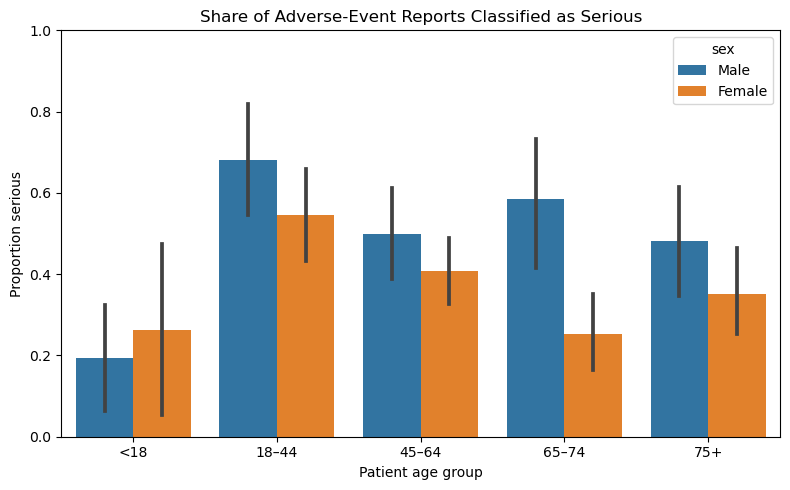

In [34]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data for plotting (df is your cleaned DataFrame)
plot_df = df.copy()

# Keep only known sex values ("0" = unknown) and plausible ages
plot_df = plot_df[plot_df["sex"].isin(["1", "2"])]
plot_df = plot_df[(plot_df["age"] >= 0) & (plot_df["age"] <= 120)]

# Readable labels
plot_df["sex"] = plot_df["sex"].map({"1": "Male", "2": "Female"})

# Numeric 0/1 versions so we can take averages (rates)
plot_df["serious_flag"] = (plot_df["serious"] == "1").astype(int)
plot_df["hosp_flag"] = (plot_df["hospitalization"] == "1").astype(int)

# Groupings
plot_df["age_group"] = pd.cut(plot_df["age"], bins=[0, 18, 45, 65, 75, 121],
                              labels=["<18", "18–44", "45–64", "65–74", "75+"],
                              right=False)
plot_df["drug_group"] = pd.cut(plot_df["num_drugs"], bins=[0, 1, 2, 4, 8, np.inf],
                               labels=["1", "2", "3–4", "5–8", "9+"])

# Plot 1: serious-report rate by age group and sex
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=plot_df, x="age_group", y="serious_flag", hue="sex",
            errorbar=("ci", 95), ax=ax)
ax.set_title("Share of Adverse-Event Reports Classified as Serious")
ax.set_xlabel("Patient age group")
ax.set_ylabel("Proportion serious")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### 2nd Visualization

A heatmap of number of drugs involved, age group, and hospitalization rate is a more indepth visualization of how these different characteristics come together to show story of adverse drug events as tracked by the FDA. This visualization shows how hospitalizations by age group and number of drugs involved in a way that a simple bar graph is unable to. It gives a better idea of how these characterisics could be potentially be used to predict the outcome of an adverse drug event; wheter it will end in hospialtization or not. 

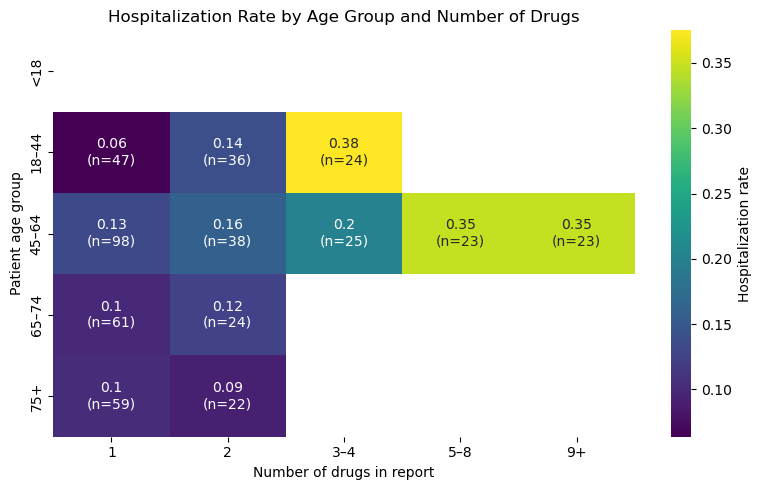

In [35]:
# Plot 2: hospitalization rate heatmap with sample sizes
rate = plot_df.pivot_table(index="age_group", columns="drug_group",
                           values="hosp_flag", aggfunc="mean", observed=True)
n = plot_df.pivot_table(index="age_group", columns="drug_group",
                        values="hosp_flag", aggfunc="size", observed=True)
labels = rate.round(2).astype(str) + "\n(n=" + n.astype(str) + ")"
rate_masked = rate.where(n >= 20)  # hide cells with too few reports

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(rate_masked, annot=labels, fmt="", cmap="viridis", ax=ax,
            cbar_kws={"label": "Hospitalization rate"})
ax.set_title("Hospitalization Rate by Age Group and Number of Drugs")
ax.set_xlabel("Number of drugs in report")
ax.set_ylabel("Patient age group")
plt.tight_layout()
plt.show()

### 3rd visualization

A supplemental visualiztion the the 2 key ones above is a box plot that has individual reports overlaid as dots. It shows how many reactions are reported for non-serious vs seriours reports. The 2nd box plot shows how many drugs are listed in reports that result in hospitalization vs reports that don't. You can see that number of drugs and number of reactions do have influence on the outcome of a report. 

               count  median      mean
serious_label                         
Non-serious      367     2.0  2.400545
Serious          277     3.0  3.642599
                  count  median      mean
hosp_label                               
Hospitalized        126     4.0  5.404762
Not hospitalized    518     2.0  2.650579


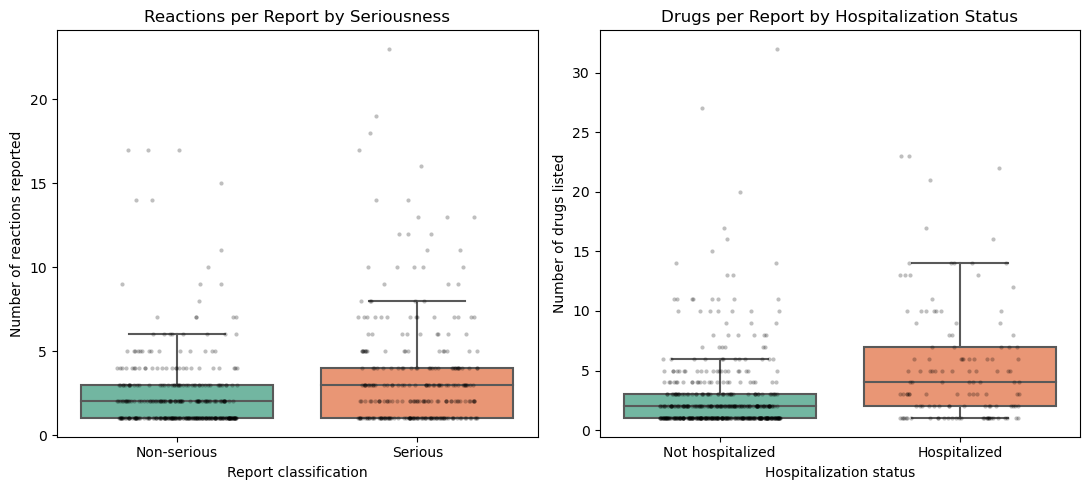

In [36]:
# Readable outcome labels
plot_df["serious_label"] = plot_df["serious_flag"].map({1: "Serious", 0: "Non-serious"})
plot_df["hosp_label"] = plot_df["hosp_flag"].map({1: "Hospitalized", 0: "Not hospitalized"})

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Left panel:
sns.boxplot(data=plot_df, x="serious_label", y="num_reactions",
            order=["Non-serious", "Serious"], showfliers=False,
            palette="Set2", ax=axes[0])
sns.stripplot(data=plot_df, x="serious_label", y="num_reactions",
              order=["Non-serious", "Serious"], color="black",
              alpha=0.25, size=3, jitter=0.25, ax=axes[0])
axes[0].set_title("Reactions per Report by Seriousness")
axes[0].set_xlabel("Report classification")
axes[0].set_ylabel("Number of reactions reported")

# Right panel: 
sns.boxplot(data=plot_df, x="hosp_label", y="num_drugs",
            order=["Not hospitalized", "Hospitalized"], showfliers=False,
            palette="Set2", ax=axes[1])
sns.stripplot(data=plot_df, x="hosp_label", y="num_drugs",
              order=["Not hospitalized", "Hospitalized"], color="black",
              alpha=0.25, size=3, jitter=0.25, ax=axes[1])
axes[1].set_title("Drugs per Report by Hospitalization Status")
axes[1].set_xlabel("Hospitalization status")
axes[1].set_ylabel("Number of drugs listed")

# Print group sizes and medians so you can cite them in your takeaway
print(plot_df.groupby("serious_label")["num_reactions"].agg(["count", "median", "mean"]))
print(plot_df.groupby("hosp_label")["num_drugs"].agg(["count", "median", "mean"]))

plt.tight_layout()
plt.show()

### 4. (20 pts) Develop at least two functions that will verify fit or other attributes of analysis from a ML model. (You don't need to identify a specific model yet).  Include markup sections which explain why these functions will be useful in analyzing a ML model.

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_predictions(y_true, y_pred):
    """
    Evaluate predictions of whether a hospitalization was recorded.

    Labels are strings: "1" = recorded, "0" = not recorded.
    "1" (recorded) is treated as the positive class.
    Actual and predicted labels must cover the same reports in the same order.

    """

    results = {
        # Overall fraction of correct predictions
        "accuracy": accuracy_score(y_true, y_pred),

        # How often predicted hospitalization matches the recorded label
        "precision_hospitalization": precision_score(
            y_true, y_pred, pos_label="1", zero_division=0
        ),

        # Fraction of reports with recorded hospitalization identified
        "recall_hospitalization": recall_score(
            y_true, y_pred, pos_label="1", zero_division=0
        ),

        # Combined measure of precision and recall
        "f1_hospitalization": f1_score(
            y_true, y_pred, pos_label="1", zero_division=0
        )
    }

    return results

In [38]:
# Made-up labels used only to test our function.
# These are NOT predictions from a trained model.
# "1" = hospitalization recorded; "0" = hospitalization not recorded.

y_true_demo = ["1", "0", "1", "0", "1", "0"]
y_pred_demo = ["1", "0", "0", "0", "1", "1"]

evaluate_predictions(y_true_demo, y_pred_demo)

{'accuracy': 0.6666666666666666,
 'precision_hospitalization': 0.6666666666666666,
 'recall_hospitalization': 0.6666666666666666,
 'f1_hospitalization': 0.6666666666666666}

In [39]:
import pandas as pd
from sklearn.metrics import confusion_matrix

def create_confusion_table(y_true, y_pred):
    """
    Compare actual and predicted hospitalization labels.

    Labels are strings: "1" = recorded, "0" = not recorded.
    Rows are actual labels; columns are predicted labels.
    """

    # Put "non recorded" first and "recorded" second.
    matrix = confusion_matrix(
        y_true, y_pred, labels=["0", "1"]
    )

    # Label the rows and columns.
    table = pd.DataFrame(
        matrix,
        index=["Actual: not recorded", "Actual: recorded"],
        columns=["Predicted: not recorded", "Predicted: recorded"]
    )

    return table
# Test using the same made-up labels from the previous cell.
# This is a demonstration, NOT actual model performance.
create_confusion_table(y_true_demo, y_pred_demo)

,Predicted: not recorded,Predicted: recorded
Actual: not recorded,2,1
Actual: recorded,1,2


### Function 1: Assessing hospitalization predictions

The evaluate_predictions function addresses our second research question: can patient and medication characteristics predict whether an adverse-event report records a hospitalization?

It takes the actual labels (y_true) and the predicted labels (y_pred), which must be for the same reports in the same order. A "1" means the report records a hospitalization, and a "0" means it does not.

The function returns four metrics:

Accuracy: the proportion of all predictions that are correct.
Precision: of the reports the model predicts as "1", the proportion that are actually "1".
Recall: of the reports that are actually "1", the proportion the model correctly predicts.
F1 score: the harmonic mean of precision and recall, which combines them into one number.
Each metric tells us something different. Recall shows how often the model misses reports that record a hospitalization, and precision shows how often its "1" predictions are right. We look at all four because accuracy alone can be high even when the model does poorly on the less common class.



### Function 2: Analyzing prediction errors

The create_confusion_table function shows a confusion matrix, with actual labels as rows and predicted labels as columns. The diagonal cells count correct predictions. The other two cells count the two kinds of errors: false positives, where the model predicts "1" for a report that is actually "0", and false negatives, where it predicts "0" for a report that is actually "1".

The first function summarizes performance as scores, while this table shows the actual number of each kind of error. That lets us see how many false alarms the model raises and how many reports it misses.

### Demonstration and future use

We tested both functions on a made-up example with six actual labels and six predictions. The example has four correct predictions, one false positive, and one false negative. Accuracy, precision, recall, and F1 all come out to about 0.667. These numbers are just a check that the functions work. They are not results from a model trained on the FDA data.

After we train a model, we will use these functions to compare its predictions with the actual labels of held-out reports that were not used in training. Because the functions only need actual and predicted labels, not the model itself, they will work for any classification algorithm we try.

One limitation is that our outcome only captures whether a hospitalization is recorded in the report. A "0" means no hospitalization appears in our prepared data. It does not confirm that the patient was never hospitalized.

### 5. (10 pts) Discuss potential ethical implications of the data and using ML to analyze it.

*Similar to Flock cameras, there are ethical concerns when using Machine Learning to handle personal patient information. Even though we are intending this project to help reduce the risk of serious ADE's for patients in the future, it is always possible that when we release the technology to the public, it can cause unintended or harmful consequences. One concern that a lot of people could have is that we are using personal patient information such as patient age, sex, medications, hospitalization, and ADE's. Possible bias or discrimination that this could lead to includes classifying certain groups as higher risk, potentially affecting how healthcare providers or insurance companies treat these patients. Moreover, not all ADE's are reported to the FDA, and we also removed reports that had missing information (such as 300+ rows missing patient ages) which could lead to inaccurate predictions that could not represent the entire population. Thus, when handling patient data using machine learning, we need to consider how it can improve drug safety as well as negatively affect future patients in a holistic manner.*